# Tổng quan Undersampling, Calibration & Threshold Tuning


# Khởi tạo môi trường chung

In [8]:
# === CELL KHOI TAO MOI TRUONG CHUNG ===
import os, sys

# Them thu muc goc vao sys.path de import duoc module src.utils
root_dir = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

from src.utils import (
    RANDOM_STATE,
    load_synthetic_data,
    load_real_data,
    get_all_undersamplers,
    get_benchmark_models,
    plot_resampled_comparison,
    plot_decision_boundary,
    plot_pr_curve,
    evaluate_sampler_and_model,
    save_figure,
    save_table
)
print('Khoi tao thanh cong! Thu muc goc:', root_dir)

Khoi tao thanh cong! Thu muc goc: d:\Pattern_Recognition\Seminar\PR_Seminar_Undersampling


## 1. Mở đầu về Undersampling (Introducing Undersampling)

### 1.1. Đặt vấn đề & Ẩn dụ câu chuyện Hai dòng họ (Montagues và Capulets)
Trong bài toán dữ liệu mất cân bằng (Imbalanced Data), việc áp dụng Oversampling đôi khi dẫn đến hiện tượng quá khớp (overfitting) do lặp lại thông tin hoặc làm phình to kích thước dữ liệu khiến thời gian huấn luyện tăng vọt. Để giải quyết theo hướng ngược lại, **Undersampling** (hay *downsampling* / *negative downsampling*) thực hiện giảm số lượng mẫu ở lớp đa số (majority/negative class).

Sách *Machine Learning for Imbalanced Data* sử dụng câu chuyện *Romeo và Juliet* để trực quan hóa các chiến lược Undersampling:
* Thị trấn Verona có hai dòng họ đối địch: **Montagues** (lớp thiểu số - *minority class*) và **Capulets** (lớp đa số - *majority class*).
* Để lập lại cân bằng quyền lực và giữ hòa bình, nhà vua quyết định loại bỏ bớt một số người thuộc dòng họ **Capulets** (lớp đa số) khỏi thị trấn theo nhiều chiến lược khác nhau.

**Hai lợi thế lớn nhất của Undersampling so với Oversampling:**
1. **Kiểm soát kích thước dữ liệu và chi phí tính toán (Data size remains in check):** Với các tập dữ liệu lớn từ hàng Terabyte đến Petabyte trên hạ tầng đám mây (AWS, Azure, GCP), việc giảm mẫu lớp đa số giúp tiết kiệm đáng kể bộ nhớ và rút ngắn thời gian huấn luyện từ nhiều ngày xuống chỉ còn vài giờ.
2. **Giảm nguy cơ Overfitting vào lớp đa số:** Việc lược bỏ bớt mẫu lớp đa số giúp mô hình tập trung hơn vào lớp thiểu số, tăng khả năng tổng quát hóa trên cả hai lớp khi gặp dữ liệu mới.

---

### 1.2. Khi nào cần tránh Undersampling lớp đa số? (When to avoid undersampling)
Undersampling không phải là giải pháp vạn năng và cần tránh trong 3 trường hợp sau:
1. **Dữ liệu huấn luyện ban đầu quá ít (Too little training data):** Nếu tập dữ liệu vốn đã nhỏ, việc cắt giảm lớp đa số sẽ gây mất mát thông tin nghiêm trọng (information loss). Khi đó nên thu thập thêm dữ liệu hoặc dùng Oversampling.
2. **Lớp đa số quan trọng ngang bằng hoặc hơn lớp thiểu số:** Trong các bài toán như lọc email rác (spam filtering), việc giữ độ chính xác cao trên lớp đa số (email hợp lệ) là tối quan trọng để tránh False Positive. Khi đó nên ưu tiên *Cost-Sensitive Learning* hoặc *Threshold Adjustment*.
3. **Khi Undersampling làm suy giảm hiệu năng hoặc gây Underfitting/Overfitting:** Một số thuật toán xóa các điểm sát biên quyết định làm biến dạng ranh giới phân lớp; hoặc giảm dữ liệu quá mức khiến mô hình bị *underfitting* (không nắm bắt được xu hướng dữ liệu) hay *overfitting* (học thuộc lòng tập dữ liệu nhỏ còn lại). Giải pháp thay thế là dùng *Ensemble Methods* hoặc *Hybrid Methods* (kết hợp Oversampling và Undersampling).

---

### 1.3. Phân loại 1: Fixed Undersampling vs. Cleaning Undersampling
Dựa trên tiêu chí dừng khi loại bỏ mẫu lớp đa số, các thuật toán được chia làm 2 nhóm:

| Tiêu chí so sánh | Fixed Undersampling Methods (Cố định) | Cleaning Undersampling Methods (Làm sạch) |
| :--- | :--- | :--- |
| **Ý tưởng cốt lõi (Key idea)** | Giảm số lượng mẫu lớp đa số về một con số cố định (thường bằng kích thước lớp thiểu số, tỷ lệ 1:1). | Nhận diện và xóa các mẫu nhiễu, dư thừa hoặc dễ phân loại sai dựa trên điều kiện hình học/lân cận mà không quan tâm số lượng mẫu còn lại là bao nhiêu. |
| **Mối quan hệ giữa các mẫu** | Không xét tương quan không gian giữa các điểm dữ liệu (trừ IHT/Cluster). | Đánh giá chặt chẽ mối quan hệ lân cận (KNN, khoảng cách) giữa các điểm dữ liệu. |
| **Tốc độ & Hiệu năng** | Nhanh hơn và dễ cài đặt hơn. | Thường giúp làm sạch biên quyết định và cho khả năng tổng quát hóa tốt hơn. |
| **Thuật toán đại diện** | `RandomUnderSampler`, `InstanceHardnessThreshold`, `ClusterCentroids`. | `EditedNearestNeighbours (ENN)`, `TomekLinks`, `NeighbourhoodCleaningRule (NCR)`. |

---

### 1.4. Phân loại 2: Khung kiến trúc 4 hướng tiếp cận (Undersampling Approaches)
Quay lại câu chuyện thị trấn Verona, nhà vua có 4 cách để loại bỏ người nhà Capulets (lớp đa số), tương ứng với 4 nhánh thuật toán mà các thành viên trong nhóm sẽ đi sâu:
1. **Remove Uniformly (Loại bỏ đồng đều toàn không gian - *Thành viên 2*):** Chọn ngẫu nhiên (`Random UnderSampling`) hoặc gom cụm giữ tâm (`Cluster Centroids`).
2. **Remove Nearby (Loại bỏ các mẫu nhiễu nằm sát lớp thiểu số - *Thành viên 3*):** Làm sạch vùng chồng lấn gần biên quyết định (`ENN`, `RENN`, `AllKNN`, `Tomek Links`, `NCR`, `Instance Hardness`).
3. **Remove Far Away (Loại bỏ các mẫu "dễ" nằm xa lớp thiểu số - *Thành viên 2*):** Giữ lại các điểm gần biên để định hình ranh giới phân lớp và xóa các điểm nằm sâu bên trong vùng lớp đa số (`Condensed Nearest Neighbors - CNN`, `NearMiss`).
4. **Remove Both Nearby and Far Away (Kết hợp xóa cả mẫu nhiễu gần biên và mẫu dễ xa biên - *Thành viên 2 & 4*):** Điển hình là `One-Sided Selection (OSS = CNN + Tomek Links)` và các phương pháp lai `SMOTEENN`, `SMOTETomek`.`

Phân phối toàn bộ tập dữ liệu (1:99): Counter({0: 9900, 1: 100})
Phân phối tập Train: Counter({0: 7920, 1: 80}) | Tập Test: Counter({0: 1980, 1: 20})
Đã lưu đồ thị tại: d:\Pattern_Recognition\Seminar\PR_Seminar_Undersampling\outputs\figures\01_fixed_vs_cleaning_overview.png


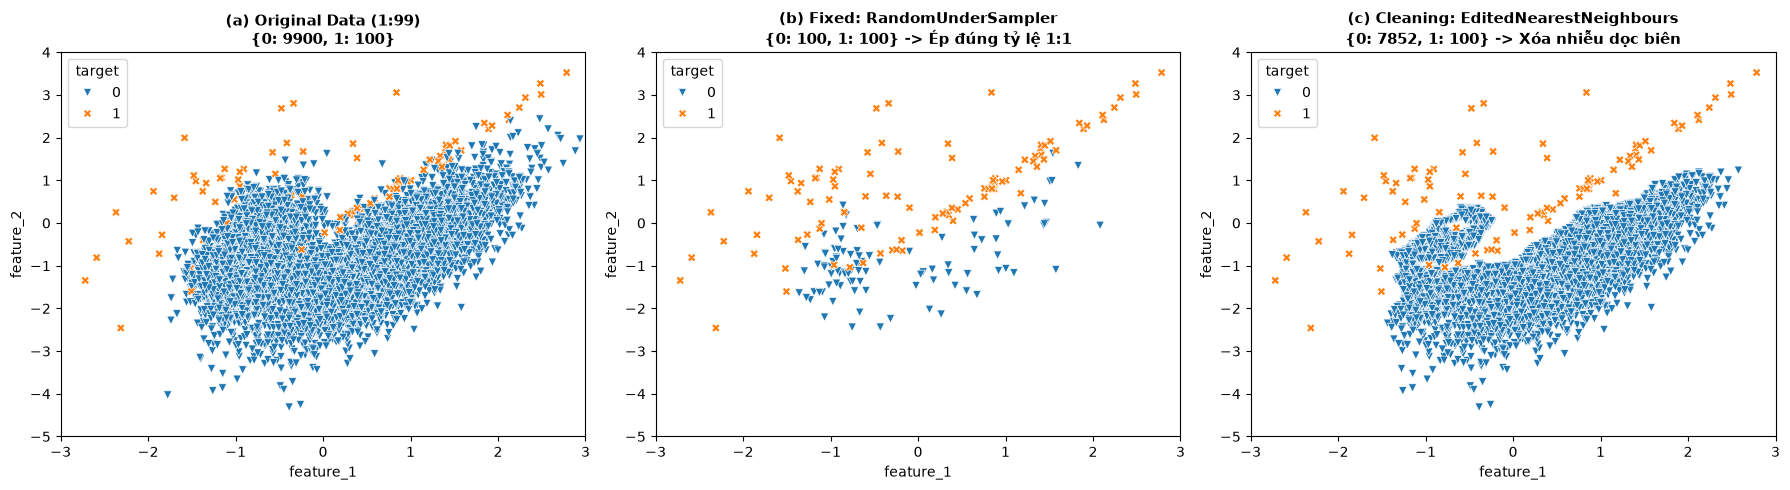

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from imblearn.under_sampling import RandomUnderSampler, EditedNearestNeighbours

# 1. Nạp dữ liệu chuẩn Chương 3 (10,000 mẫu, tỷ lệ 1:99, class_sep=0.79, random_state=81)
X_train, X_test, y_train, y_test, X_full, y_full = load_synthetic_data(class_sep=0.79)
print("Phân phối toàn bộ tập dữ liệu (1:99):", Counter(y_full))
print("Phân phối tập Train:", Counter(y_train), "| Tập Test:", Counter(y_test))

# 2. Thực nghiệm so sánh cơ chế Fixed (RUS) và Cleaning (ENN) trên tập dữ liệu 2D
rus_fixed = RandomUnderSampler(sampling_strategy=1.0, random_state=RANDOM_STATE)
X_fixed, y_fixed = rus_fixed.fit_resample(X_full, y_full)

enn_cleaning = EditedNearestNeighbours(sampling_strategy="auto", n_neighbors=200, kind_sel="all")
X_clean, y_clean = enn_cleaning.fit_resample(X_full, y_full)

# 3. Vẽ đồ thị 3 khung: Dữ liệu gốc vs Fixed (RUS) vs Cleaning (ENN)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets = [
    (X_full, y_full, f"(a) Original Data (1:99)\n{dict(Counter(y_full))}"),
    (X_fixed, y_fixed, f"(b) Fixed: RandomUnderSampler\n{dict(Counter(y_fixed))} -> Ép đúng tỷ lệ 1:1"),
    (X_clean, y_clean, f"(c) Cleaning: EditedNearestNeighbours\n{dict(Counter(y_clean))} -> Xóa nhiễu dọc biên")
]

for ax, (X_plot, y_plot, title) in zip(axes, datasets):
    sns.scatterplot(
        x=X_plot["feature_1"], y=X_plot["feature_2"],
        hue=y_plot, style=y_plot, markers={0: "v", 1: "X"}, ax=ax
    )
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("feature_1")
    ax.set_ylabel("feature_2")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-5, 4)

plt.tight_layout()
save_figure(fig, "01_fixed_vs_cleaning_overview.png")
plt.show()

## 2. Hiệu chuẩn xác suất sau khi Undersampling (Model Calibration)

### 2.1. Tại sao Undersampling làm lệch xác suất dự đoán (Miscalibration)?
* Giả sử tập dữ liệu thực tế có tỷ lệ mất cân bằng là $1:99$, tức xác suất tiên nghiệm (prior probability) của lớp thiểu số ngoài thực tế chỉ là $P(y=1) = 0.01$.
* Khi áp dụng **Random UnderSampling (RUS)** để đưa tập huấn luyện về tỷ lệ cân bằng $1:1$, xác suất tiên nghiệm trên tập huấn luyện bị đẩy lên thành $P_s(y=1) = 0.50$.
* Hệ quả là mô hình học trên tập đã giảm mẫu sẽ **ước lượng quá cao (overestimate)** xác suất thuộc lớp thiểu số khi đem ra dự đoán trên tập kiểm tra (Test set) có phân phối thực tế $1:99$. Một mẫu thực chất chỉ có $5\%$ khả năng là dương tính có thể bị mô hình báo xác suất lên tới $70\% - 80\%$.

### 2.2. Thước đo đánh giá mức độ hiệu chuẩn
1. **Đường cong hiệu chuẩn (Calibration Curve / Reliability Plot):** Biểu diễn xác suất dự đoán trung bình (trục hoành) so với tỷ lệ dương tính thực tế trong từng khoảng xác suất (trục tung). Mô hình hiệu chuẩn hoàn hảo sẽ nằm dọc theo đường chéo $y = x$.
2. **Brier Score:** Đo sai số bình phương trung bình (MSE) giữa xác suất dự đoán $\hat{p}_i \in [0, 1]$ và nhãn thực tế $y_i \in \{0, 1\}$:
   $$\text{Brier Score} = \frac{1}{N} \sum_{i=1}^{N} (\hat{p}_i - y_i)^2$$
   *(Giá trị Brier Score càng nhỏ thì xác suất dự đoán càng chuẩn xác).*

### 2.3. Các phương pháp Hiệu chuẩn lại xác suất (Recalibration Techniques)
1. **Hiệu chuẩn giải tích theo Bayes (Dal Pozzolo et al., 2015 - Reference [4] Chương 3):**
   Gọi $\beta = \frac{N_0^{\text{resampled}}}{N_0^{\text{original}}}$ là tỷ lệ giữ lại của lớp đa số sau khi Undersampling, và $p_s$ là xác suất dự đoán từ mô hình huấn luyện trên tập đã giảm mẫu. Xác suất thực tế $p$ trên phân phối gốc được hiệu chỉnh trực tiếp bằng công thức:
   $$p = \frac{\beta \cdot p_s}{(\beta - 1) \cdot p_s + 1}$$
2. **Platt's Scaling (Sigmoid Calibration):** Huấn luyện thêm một hàm Logistic (Sigmoid) trên tập Validation giữ nguyên phân phối gốc để ánh xạ đầu ra của mô hình về xác suất chuẩn. Phù hợp khi đường cong sai lệch có dạng chữ S hoặc kích thước tập Validation nhỏ.
3. **Isotonic Regression:** Phương pháp phi tham số khớp một hàm bậc thang đơn điệu không giảm. Linh hoạt hơn Platt's Scaling nhưng cần tập dữ liệu hiệu chuẩn đủ lớn để tránh overfitting.

Đã lưu đồ thị tại: d:\Pattern_Recognition\Seminar\PR_Seminar_Undersampling\outputs\figures\01_calibration_curves.png


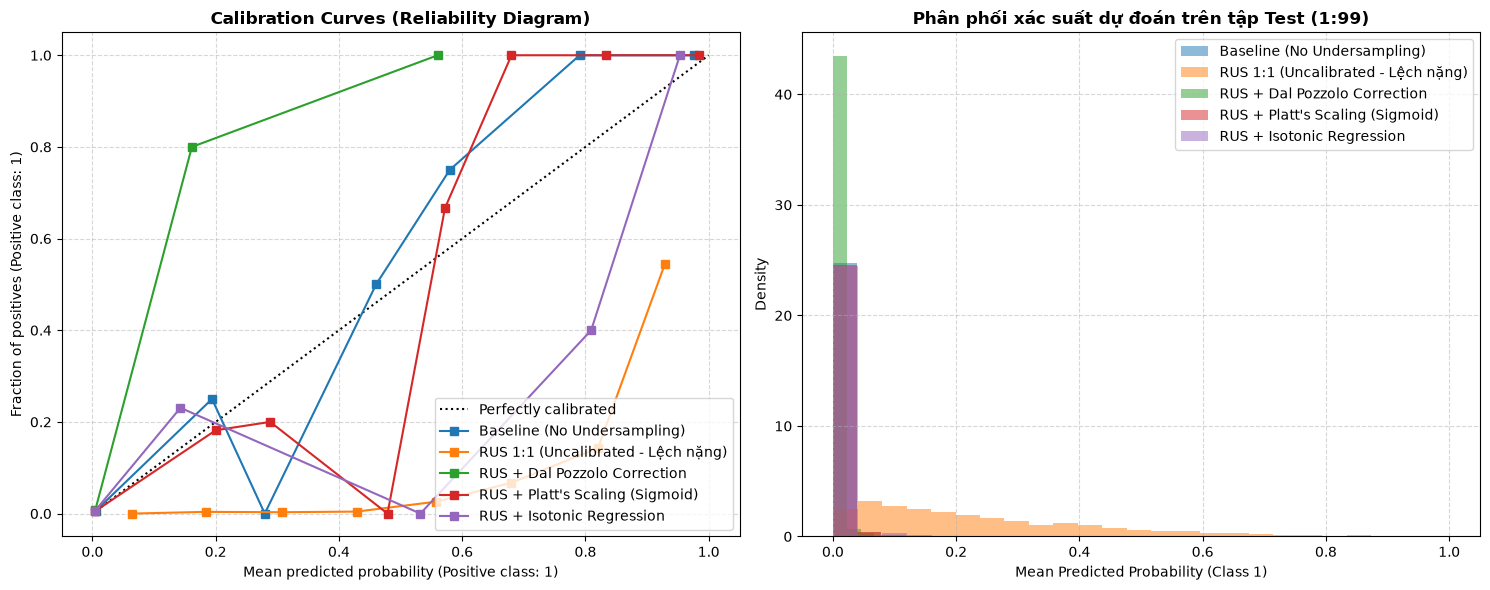

Đã lưu bảng số liệu tại: d:\Pattern_Recognition\Seminar\PR_Seminar_Undersampling\outputs\tables\01_calibration_metrics.csv


,Configuration,True Positive Prior,Mean Predicted Prob,Prob Bias (|Mean - Prior|),Brier Score (Lower is better),PR-AUC
0,Baseline (No Undersampling),0.01,0.0091,0.0009,0.0074,0.4092
1,RUS 1:1 (Uncalibrated - Lệch nặng),0.01,0.2381,0.2281,0.0882,0.4241
2,RUS + Dal Pozzolo Correction,0.01,0.0052,0.0048,0.0086,0.4241
3,RUS + Platt's Scaling (Sigmoid),0.01,0.0093,0.0007,0.0073,0.4241
4,RUS + Isotonic Regression,0.01,0.0090,0.0010,0.0077,0.3783


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.model_selection import train_test_split
from sklearn.metrics import brier_score_loss, average_precision_score
from imblearn.under_sampling import RandomUnderSampler

# 1. Chia tập Train gốc (8000 mẫu) thành Sub-Train (80%) để huấn luyện RUS
#    và Calibration Set (20% giữ nguyên phân phối thực tế 1:99) để khớp Platt/Isotonic
X_subtrain, X_calib, y_subtrain, y_calib = train_test_split(
    X_train, y_train, stratify=y_train, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Huấn luyện mô hình Baseline trên dữ liệu gốc (không Undersampling)
clf_base = LogisticRegression(random_state=RANDOM_STATE)
clf_base.fit(X_subtrain, y_subtrain)
prob_base = clf_base.predict_proba(X_test)[:, 1]

# 3. Huấn luyện mô hình trên dữ liệu đã Random UnderSampling (tỷ lệ 1:1) -> Chưa hiệu chuẩn
rus = RandomUnderSampler(sampling_strategy=1.0, random_state=RANDOM_STATE)
X_rus, y_rus = rus.fit_resample(X_subtrain, y_subtrain)

clf_rus_uncal = LogisticRegression(random_state=RANDOM_STATE)
clf_rus_uncal.fit(X_rus, y_rus)
prob_rus_uncal = clf_rus_uncal.predict_proba(X_test)[:, 1]

# 4. Phương pháp 1: Hiệu chuẩn giải tích Dal Pozzolo et al. (2015) dựa trên tỷ lệ giảm mẫu beta
n_maj_orig = (y_subtrain == 0).sum()
n_maj_res = (y_rus == 0).sum()
beta = n_maj_res / n_maj_orig  # Tỷ lệ mẫu lớp đa số được giữ lại (~0.0101)

prob_rus_dal_pozzolo = (beta * prob_rus_uncal) / ((beta - 1.0) * prob_rus_uncal + 1.0)

# 5. Phương pháp 2 & 3: Platt's Scaling (sigmoid) và Isotonic Regression trên tập X_calib
# (Hỗ trợ tương thích cả scikit-learn >= 1.6 dùng FrozenEstimator và bản cũ dùng cv="prefit")
try:
    clf_platt = CalibratedClassifierCV(FrozenEstimator(clf_rus_uncal), method="sigmoid")
    clf_iso = CalibratedClassifierCV(FrozenEstimator(clf_rus_uncal), method="isotonic")
except Exception:
    clf_platt = CalibratedClassifierCV(clf_rus_uncal, method="sigmoid", cv="prefit")
    clf_iso = CalibratedClassifierCV(clf_rus_uncal, method="isotonic", cv="prefit")

clf_platt.fit(X_calib, y_calib)
clf_iso.fit(X_calib, y_calib)

prob_rus_platt = clf_platt.predict_proba(X_test)[:, 1]
prob_rus_iso = clf_iso.predict_proba(X_test)[:, 1]

# 6. Vẽ biểu đồ Calibration Curve (Reliability Plot) & Phân phối xác suất dự đoán
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

probs_dict = {
    "Baseline (No Undersampling)": prob_base,
    "RUS 1:1 (Uncalibrated - Lệch nặng)": prob_rus_uncal,
    "RUS + Dal Pozzolo Correction": prob_rus_dal_pozzolo,
    "RUS + Platt's Scaling (Sigmoid)": prob_rus_platt,
    "RUS + Isotonic Regression": prob_rus_iso,
}

for name, prob in probs_dict.items():
    CalibrationDisplay.from_predictions(
        y_test, prob, n_bins=8, name=name, ax=axes[0]
    )
    axes[1].hist(prob, bins=25, alpha=0.5, label=name, density=True)

axes[0].set_title("Calibration Curves (Reliability Diagram)", fontsize=12, fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].set_title("Phân phối xác suất dự đoán trên tập Test (1:99)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Mean Predicted Probability (Class 1)")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
save_figure(fig, "01_calibration_curves.png")
plt.show()

# 7. Xuất bảng so sánh định lượng Brier Score và Xác suất trung bình
true_prior = y_test.mean()
calib_rows = []
for name, prob in probs_dict.items():
    calib_rows.append({
        "Configuration": name,
        "True Positive Prior": round(true_prior, 4),
        "Mean Predicted Prob": round(prob.mean(), 4),
        "Prob Bias (|Mean - Prior|)": round(abs(prob.mean() - true_prior), 4),
        "Brier Score (Lower is better)": round(brier_score_loss(y_test, prob), 4),
        "PR-AUC": round(average_precision_score(y_test, prob), 4)
    })

df_calib = pd.DataFrame(calib_rows)
save_table(df_calib, "01_calibration_metrics.csv")
df_calib

## 3. Dời ngưỡng quyết định (Threshold Tuning / Threshold Adjustment)

### 3.1. Tại sao ngưỡng mặc định $\tau = 0.5$ không phù hợp cho dữ liệu mất cân bằng?
* Theo mặc định, các bộ phân lớp nhị phân gán nhãn Lớp 1 (Positive) nếu xác suất dự đoán $\hat{p} \ge 0.5$ và Lớp 0 (Negative) nếu $\hat{p} < 0.5$.
* Các độ đo như Accuracy, Precision, Recall, $F_1$ và $F_2$ đều là các độ đo **phụ thuộc ngưỡng (threshold-dependent metrics)**, trong khi đường cong ROC và PR là **độc lập ngưỡng (threshold-independent)**.
* Khi dữ liệu mất cân bằng hoặc sau khi thực hiện Undersampling + Calibration, ngưỡng mặc định $0.5$ thường quá cao đối với xác suất thực tế của lớp thiểu số (khiến Recall rất thấp, bỏ sót nhiều mẫu dương tính) hoặc quá thấp nếu chưa hiệu chuẩn (khiến False Positive tăng vọt).
* Quy luật đánh đổi khi thay đổi ngưỡng $\tau$:
  * **Tăng ngưỡng $\tau$:** Mô hình thận trọng hơn khi dự đoán Lớp 1 $\rightarrow$ **Precision tăng**, **Recall giảm**.
  * **Giảm ngưỡng $\tau$:** Mô hình dễ dàng bắt được Lớp 1 hơn $\rightarrow$ **Recall tăng**, **Precision giảm**.

### 3.2. Tối ưu hóa ngưỡng theo độ đo mục tiêu ($F_2$-Score)
Trong các bài toán phát hiện gian lận hoặc chẩn đoán bệnh (như tập dữ liệu `thyroid_sick`), chi phí bỏ sót mẫu dương tính (False Negative) nghiêm trọng hơn nhiều so với báo động giả (False Positive). Do đó, ta ưu tiên tối đa hóa độ đo **$F_2$-score** ($\beta = 2$, đặt trọng số cho Recall cao gấp đôi Precision):
$$F_2 = \frac{(1 + 2^2) \times \text{Precision} \times \text{Recall}}{(2^2 \times \text{Precision}) + \text{Recall}} = \frac{5 \times \text{Precision} \times \text{Recall}}{(4 \times \text{Precision}) + \text{Recall}}$$
Bài toán Dời ngưỡng tìm giá trị $\tau^*$ trên đường cong Precision-Recall sao cho:
$$\tau^* = \arg\max_{\tau \in (0, 1)} F_2(\tau)$$

---

## 4. Tổng kết & Ứng dụng Undersampling trong thực tế (Production Case Studies)

Trong các hệ thống công nghiệp quy mô lớn (Big Data), dữ liệu không chỉ mất cân bằng nghiêm trọng mà còn có dung lượng hàng trăm triệu bản ghi mỗi ngày. Dưới đây là cách 3 tập đoàn công nghệ lớn áp dụng Undersampling vào hệ thống thực tế:

| Tập đoàn | Bài toán thực tế & Quy mô dữ liệu | Chiến lược Undersampling & Hậu xử lý | Kết quả đạt được |
| :--- | :--- | :--- | :--- |
| **Meta (Facebook)** *(He et al., 2014)* | Dự đoán tỷ lệ nhấp chuột quảng cáo (**Ad Click-Through Rate - CTR**). Hàng trăm triệu mẫu mỗi ngày, tỷ lệ click

Đã lưu đồ thị tại: d:\Pattern_Recognition\Seminar\PR_Seminar_Undersampling\outputs\figures\01_threshold_tuning.png


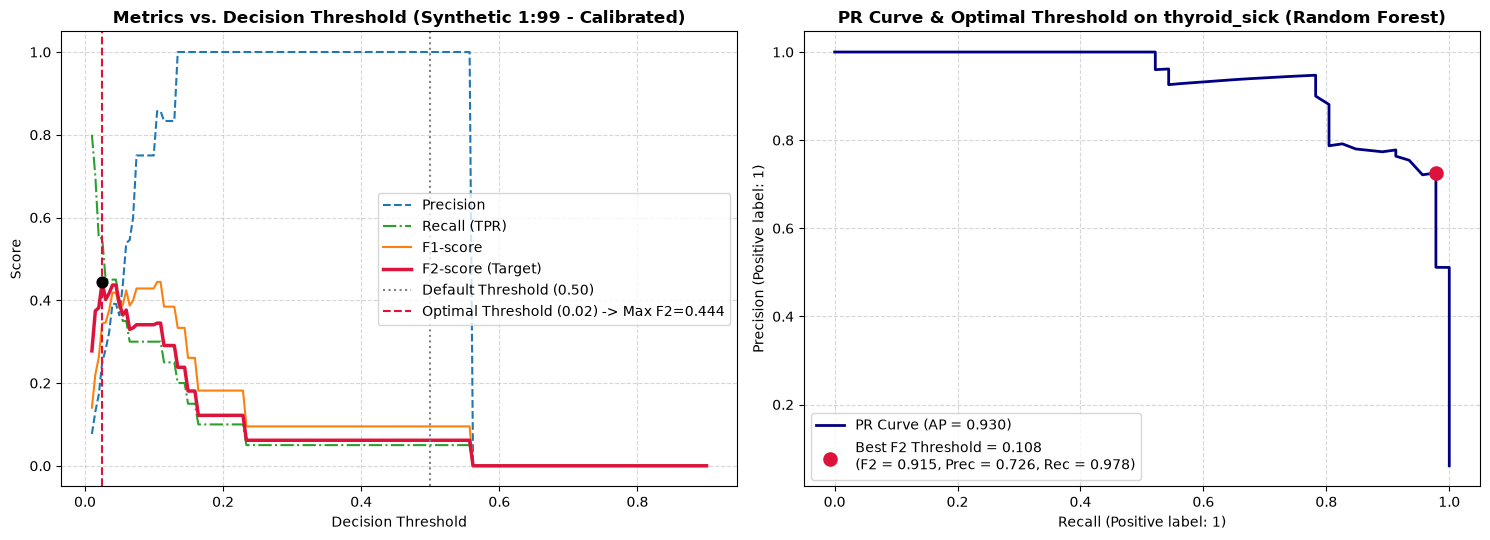

Đã lưu bảng số liệu tại: d:\Pattern_Recognition\Seminar\PR_Seminar_Undersampling\outputs\tables\01_threshold_tuning_summary.csv


,Dataset,Configuration,Threshold,PR-AUC,F2-Score,F1-Score,Precision,Recall
0,Synthetic (1:99),1. RUS Uncalibrated (Default 0.5),0.500,0.4241,0.2778,0.1404,0.0769,0.8000
1,Synthetic (1:99),2. RUS Calibrated (Default 0.5),0.500,0.4241,0.0617,0.0952,1.0000,0.0500
2,Synthetic (1:99),3. RUS Calibrated + Tuned Threshold,0.025,0.4241,0.4435,0.3438,0.2500,0.5500
3,thyroid_sick,1. RUS Uncalibrated (Default 0.5),0.500,0.9304,0.8654,0.7377,0.5921,0.9783
4,thyroid_sick,2. RUS Calibrated (Default 0.5),0.500,0.9304,0.5742,0.6761,0.9600,0.5217
5,thyroid_sick,3. RUS Calibrated + Tuned Threshold,0.108,0.9304,0.9146,0.8333,0.7258,0.9783


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_recall_curve,
    fbeta_score,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)
from imblearn.under_sampling import RandomUnderSampler

# ==============================================================================
# PHẦN A: QUÉT NGƯỠNG (THRESHOLD TUNING) TRÊN DỮ LIỆU ĐÃ HIỆU CHUẨN (SYNTHETIC)
# ==============================================================================
# Sử dụng xác suất đã hiệu chuẩn bằng công thức Dal Pozzolo (prob_rus_dal_pozzolo) ở Mục 2
# và so sánh trên một lưới ngưỡng từ 0.01 đến 0.90
thresholds = np.linspace(0.01, 0.90, 180)
prec_list, rec_list, f1_list, f2_list = [], [], [], []

for t in thresholds:
    preds_t = (prob_rus_dal_pozzolo >= t).astype(int)
    prec_list.append(precision_score(y_test, preds_t, zero_division=0))
    rec_list.append(recall_score(y_test, preds_t, zero_division=0))
    f1_list.append(f1_score(y_test, preds_t, zero_division=0))
    f2_list.append(fbeta_score(y_test, preds_t, beta=2.0, zero_division=0))

best_idx_syn = int(np.argmax(f2_list))
best_thresh_syn = thresholds[best_idx_syn]
best_f2_syn = f2_list[best_idx_syn]

# ==============================================================================
# PHẦN B: THỰC NGHIỆM TRÊN DỮ LIỆU THỰC TẾ (THYROID_SICK)
# ==============================================================================
X_tr_real, X_te_real, y_tr_real, y_te_real = load_real_data("thyroid_sick")

rus_real = RandomUnderSampler(sampling_strategy=1.0, random_state=RANDOM_STATE)
X_tr_real_rus, y_tr_real_rus = rus_real.fit_resample(X_tr_real, y_tr_real)

rf_real = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_real.fit(X_tr_real_rus, y_tr_real_rus)

# Hiệu chuẩn Dal Pozzolo cho tập thyroid_sick
beta_real = (y_tr_real_rus == 0).sum() / (y_tr_real == 0).sum()
prob_real_uncal = rf_real.predict_proba(X_te_real)[:, 1]
prob_real_cal = (beta_real * prob_real_uncal) / ((beta_real - 1.0) * prob_real_uncal + 1.0)

# Tìm ngưỡng tối ưu F2 trên đường cong Precision-Recall của thyroid_sick
prec_curve, rec_curve, pr_thresholds = precision_recall_curve(y_te_real, prob_real_cal)
f2_curve = (5 * prec_curve * rec_curve) / (4 * prec_curve + rec_curve + 1e-12)
best_idx_real = int(np.argmax(f2_curve[:-1]))
best_thresh_real = pr_thresholds[best_idx_real]

# ==============================================================================
# VẼ ĐỒ THỊ MINH HỌA THRESHOLD TUNING
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Biểu đồ 1: Sự biến thiên của Precision, Recall, F1, F2 theo Threshold (Synthetic Data)
axes[0].plot(thresholds, prec_list, label="Precision", linestyle="--", color="tab:blue")
axes[0].plot(thresholds, rec_list, label="Recall (TPR)", linestyle="-.", color="tab:green")
axes[0].plot(thresholds, f1_list, label="F1-score", color="tab:orange")
axes[0].plot(thresholds, f2_list, label="F2-score (Target)", linewidth=2.5, color="crimson")
axes[0].axvline(0.5, color="gray", linestyle=":", label="Default Threshold (0.50)")
axes[0].axvline(best_thresh_syn, color="crimson", linestyle="--",
                label=f"Optimal Threshold ({best_thresh_syn:.2f}) -> Max F2={best_f2_syn:.3f}")
axes[0].scatter([best_thresh_syn], [best_f2_syn], color="black", zorder=5, s=60)
axes[0].set_title("Metrics vs. Decision Threshold (Synthetic 1:99 - Calibrated)", fontweight="bold")
axes[0].set_xlabel("Decision Threshold")
axes[0].set_ylabel("Score")
axes[0].legend(loc="center right")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Biểu đồ 2: Đường cong PR và điểm Optimal Threshold trên tập thực tế thyroid_sick
ap_real = average_precision_score(y_te_real, prob_real_cal)
axes[1].plot(rec_curve, prec_curve, color="navy", linewidth=2, label=f"PR Curve (AP = {ap_real:.3f})")
axes[1].scatter(
    rec_curve[best_idx_real], prec_curve[best_idx_real],
    color="crimson", marker="o", s=90, zorder=5,
    label=f"Best F2 Threshold = {best_thresh_real:.3f}\n(F2 = {f2_curve[best_idx_real]:.3f}, "
          f"Prec = {prec_curve[best_idx_real]:.3f}, Rec = {rec_curve[best_idx_real]:.3f})"
)
axes[1].set_title("PR Curve & Optimal Threshold on thyroid_sick (Random Forest)", fontweight="bold")
axes[1].set_xlabel("Recall (Positive label: 1)")
axes[1].set_ylabel("Precision (Positive label: 1)")
axes[1].legend(loc="lower left")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
save_figure(fig, "01_threshold_tuning.png")
plt.show()

# ==============================================================================
# BẢNG TỔNG HỢP SO SÁNH HIỆU QUẢ DỜI NGƯỠNG (DEFAULT 0.5 vs. OPTIMAL THRESHOLD)
# ==============================================================================
def summarize_threshold_effect(dataset_label, y_true, probs, thresh, note):
    preds = (probs >= thresh).astype(int)
    return {
        "Dataset": dataset_label,
        "Configuration": note,
        "Threshold": round(float(thresh), 3),
        "PR-AUC": round(average_precision_score(y_true, probs), 4),
        "F2-Score": round(fbeta_score(y_true, preds, beta=2.0, zero_division=0), 4),
        "F1-Score": round(f1_score(y_true, preds, zero_division=0), 4),
        "Precision": round(precision_score(y_true, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_true, preds, zero_division=0), 4),
    }

summary_rows = [
    summarize_threshold_effect("Synthetic (1:99)", y_test, prob_rus_uncal, 0.50, "1. RUS Uncalibrated (Default 0.5)"),
    summarize_threshold_effect("Synthetic (1:99)", y_test, prob_rus_dal_pozzolo, 0.50, "2. RUS Calibrated (Default 0.5)"),
    summarize_threshold_effect("Synthetic (1:99)", y_test, prob_rus_dal_pozzolo, best_thresh_syn, "3. RUS Calibrated + Tuned Threshold"),
    summarize_threshold_effect("thyroid_sick", y_te_real, prob_real_uncal, 0.50, "1. RUS Uncalibrated (Default 0.5)"),
    summarize_threshold_effect("thyroid_sick", y_te_real, prob_real_cal, 0.50, "2. RUS Calibrated (Default 0.5)"),
    summarize_threshold_effect("thyroid_sick", y_te_real, prob_real_cal, best_thresh_real, "3. RUS Calibrated + Tuned Threshold"),
]

df_thresh_summary = pd.DataFrame(summary_rows)
save_table(df_thresh_summary, "01_threshold_tuning_summary.csv")
df_thresh_summary